# Combined M–c + Magnitude-Gap Recovery — Triaxial NFW + Miscentering (Unbiased)

Same setup as `combined_recovery_lensing_triaxial_unbiased.ipynb`, but with the
**Rayleigh + delta-function miscentering model** re-enabled in the simulation:

- A fraction $f_{\rm cen}$ of clusters are correctly centred.
- The remaining $(1-f_{\rm cen})$ have a positional offset drawn from a
  Rayleigh distribution with scale $\sigma_{\rm off}$ [Mpc/$h$].

This combines the two simulation-only systematics — triaxiality and miscentering
— and applies the same analysis-side mitigation that gave unbiased recovery in
the triaxial-only case: a **radial cut** $R \ge R_{\rm min,fit}$ before the
joint likelihood evaluation.  Miscentering smears the inner profile in a way
that compounds the spherical-NFW model mismatch, so the inner-bin cut also helps
suppress the miscentering-induced bias.

The simulation and the analysis are otherwise identical to
`combined_recovery_lensing_triaxial_miscentering.ipynb` plus the radial cut.

## Mechanism reminder (triaxiality bias)

With miscentering off and `scatter_logc = 0`, `poisson_richness = False`, the
spherical-NFW model is misspecified against the triaxial truth.  This biases
$c_0$ low by $\sim 10$–$20\%$ and (via the $c_0$–$\gamma$ degeneracy) $\gamma$
high by $\sim +0.1$:
$$
  \Delta\gamma \approx \frac{-\Delta\log_{10}c_0}{\langle\log_{10}(\Delta m/\Delta m_{\rm ref})\rangle}
  \approx \frac{0.08}{0.7} \approx +0.11.
$$
The triaxiality mismatch is maximal at $R \lesssim r_s$ where the NFW peak is
shape-sensitive; the $1/R^2$ outer tail is nearly shape-independent.

## Miscentering effect on the profile

A miscentred measurement convolves the true $\Delta\Sigma$ with the offset PDF
in projection.  This (a) suppresses the central peak and (b) broadens the
transition region around $R \sim \sigma_{\rm off}$, again most strongly at
small $R$.  The same radial cut that mitigates the triaxiality bias therefore
also mitigates the miscentering bias.

## The fix (analysis-only)

Restrict the radial range fed to the joint likelihood to
$R \ge R_{\rm min,fit}$.  The simulation, forward model, and sampler are
unchanged — only the data, covariance, and `radii` array slice are restricted.

## DES Y3 redshift distributions

This run uses **DES Y3-like redshift distributions** for both the cluster lens
sample and the background source sample:

- **Cluster $n(z)$**: redMaPPer-Y3-like — concentrated in $z\in[0.2, 0.65]$,
  approximated here as a volume-weighted distribution $P(z)\propto z^2$ on that
  range.  Mean $\bar z \approx 0.49$.
- **Source $n(z)$**: metacal-Y3-like — Smail–Schechter form
  $n(z)\propto (z/z_0)^{\alpha}\exp[-(z/z_0)^{\beta}]$ with
  $z_0=0.4$, $\alpha=2$, $\beta=1.5$.  Peaks near $z\approx 0.4$–$0.5$, mean
  $\bar z \approx 0.66$, tail extends to $z\sim 2$
  \citep{Myles2021,MacCrann2021}.

Cluster $z$ values are drawn by inverse-CDF and the truth catalogue is obtained
by reweighting an oversampled uniform-$z$ pool from `generate_truth_catalog`,
preserving the mass-redshift correlation imposed by the Tinker08 HMF.  Source
$z$ values overwrite the uniform default in `make_simple_random_cat` after the
catalogue is built.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table

from destacking.simulation import generate_truth_catalog, make_test_data
from destacking.simulation import des_y3_cluster_pdf, sample_des_y3_cluster_z, des_y3_source_pdf, sample_des_y3_source_z
from destacking.fitting import run_sampler_combined
from destacking.relations import c_DuttonMaccio
from destacking.model import _MC_M_PIVOT_LOG, _MC_Z_REF
from scipy.stats import norm as sp_norm, truncnorm as sp_truncnorm

from xlensing.sims import (
    make_simple_random_cat,
    apply_triaxial_NFW_shear_region,
    sample_triaxial_shapes,
    r_vir,
    project_ellipsoid,
)
from xlensing.data import metacal_cluster_lensing, signal
import ngmix
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)

try:
    import corner
except ImportError:
    corner = None

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(it, **kwargs): return it

Lookup tables loaded!


## Parameters

In [2]:
N_CLUSTERS   = 5000          # number of clusters
TRUE_GAMMA   = 0.2          # gamma [dex/dex]: d(log10 c)/d(log10(delta_m/delta_m_ref))
DELTA_M_REF  = 0.1          # reference magnitude gap [mag]
RADII        = np.logspace(-0.8, 0.8, 12)   # projected radii [Mpc]

# ── Triaxiality-bias mitigation ──
R_MIN_FIT    = 0.5          # Mpc — discard radial bins below this radius in the fit

# ── Miscentering model ──
F_CEN          = 0.64       # fraction of correctly centred clusters
SIGMA_OFF_MPC_H = 0.32      # Rayleigh scale for miscentred offsets [Mpc/h]

# ── DES Y3 redshift distributions ──
DES_Y3_Z_CLUSTER_RANGE = (0.2, 0.65)   # redMaPPer Y3 range
DES_Y3_Z_SRC_ALPHA     = 2.0           # Smail-Schechter alpha for source n(z)
DES_Y3_Z_SRC_BETA      = 1.5           # Smail-Schechter beta  for source n(z)
DES_Y3_Z_SRC_Z0        = 0.4           # Smail-Schechter z0    for source n(z)
N_OVERSAMPLE_CLUSTER   = 5             # truth-pool oversample factor

# ── Galaxy survey parameters ──
DENSITY         = 30
WIDTH_RAD       = 0.006     # field half-width [rad] ≈ ±20 arcmin
Z_SRC_RANGE     = (0.0, 2.5)   # extended to cover DES Y3 source tail; z overwritten below
SHAPE_NOISE     = 0.27
NOISE_FLOOR_COV = 1e4       # [(M_sun/pc²)²]

# Bin limits
log_r  = np.log10(RADII)
dlog   = np.diff(log_r)[0]
edges  = np.logspace(log_r[0] - dlog/2, log_r[-1] + dlog/2, len(RADII) + 1)
bin_limits = np.column_stack([edges[:-1], edges[1:]])
N_BINS = len(RADII)

print(f'TRUE_GAMMA  = {TRUE_GAMMA}')
print(f'DELTA_M_REF = {DELTA_M_REF} mag')
print(f'R_MIN_FIT   = {R_MIN_FIT} Mpc  (triaxiality + miscentering mitigation)')
print(f'F_CEN       = {F_CEN}  ({100*(1-F_CEN):.0f}% miscentred)')
print(f'SIGMA_OFF   = {SIGMA_OFF_MPC_H} Mpc/h')
print(f'Cluster z   ~ DES Y3 redMaPPer  in {DES_Y3_Z_CLUSTER_RANGE}')
print(f'Source  z   ~ DES Y3 metacal    (Smail: a={DES_Y3_Z_SRC_ALPHA}, b={DES_Y3_Z_SRC_BETA}, z0={DES_Y3_Z_SRC_Z0})')
print(f'M_pivot_log = {_MC_M_PIVOT_LOG},  z_ref = {_MC_Z_REF}')


TRUE_GAMMA  = 0.2
DELTA_M_REF = 0.1 mag
R_MIN_FIT   = 0.5 Mpc  (triaxiality + miscentering mitigation)
F_CEN       = 0.64  (36% miscentred)
SIGMA_OFF   = 0.32 Mpc/h
Cluster z   ~ DES Y3 redMaPPer  in (0.2, 0.65)
Source  z   ~ DES Y3 metacal    (Smail: a=2.0, b=1.5, z0=0.4)
M_pivot_log = 14.0,  z_ref = 0.35


## Seeds

A single switch controls reproducibility of every RNG in the pipeline.

* `MASTER_SEED = <int>` — every truth-catalogue, triaxial, miscentering,
  observable, and per-cluster lensing draw is derived from this value, so
  the whole pipeline is bit-for-bit reproducible.
* `MASTER_SEED = None` — every RNG falls back to OS entropy and produces a
  different realisation each run.


In [ ]:
# Set MASTER_SEED to an integer for a reproducible run, or to None for a
# fresh-entropy realisation every time.  Every other seed in the notebook is
# derived from this single value via the _seed() helper below.
MASTER_SEED = 42       # or None

def _seed(offset):
    """MASTER_SEED + offset, or None when MASTER_SEED is None."""
    return None if MASTER_SEED is None else MASTER_SEED + int(offset)

print(f'MASTER_SEED = {MASTER_SEED}'
      + ('  (fresh OS entropy every RNG)' if MASTER_SEED is None
         else '  (fully reproducible run)'))


## DES Y3 redshift distributions — definitions and visualisation

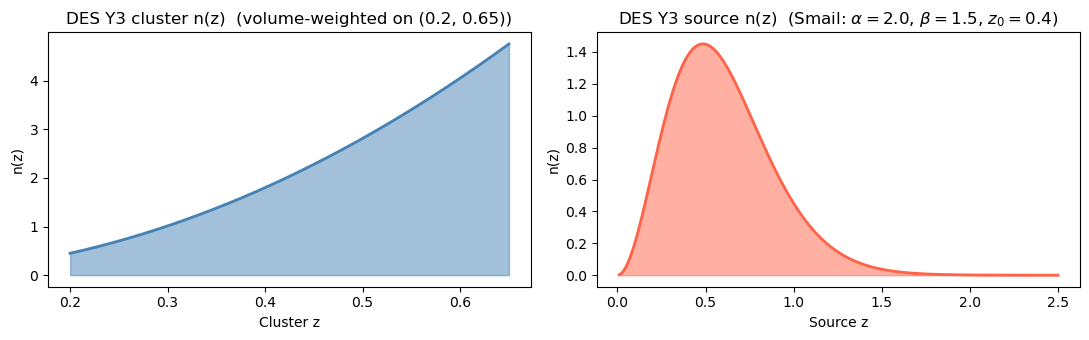

Cluster mean z: 0.498
Source  mean z: 0.602


/tmp/ipykernel_196810/1509088475.py:30: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  print(f'Cluster mean z: {np.trapz(z_grid * p_cl, z_grid):.3f}')
/tmp/ipykernel_196810/1509088475.py:35: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  print(f'Source  mean z: {np.trapz(z_grid * p_sr, z_grid):.3f}')


In [3]:


# ── Visualise the two n(z) distributions ──
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

z_cl = np.linspace(*DES_Y3_Z_CLUSTER_RANGE, 400)
axes[0].fill_between(z_cl, des_y3_cluster_pdf(z_cl, *DES_Y3_Z_CLUSTER_RANGE),
                     color='steelblue', alpha=0.5)
axes[0].plot(z_cl, des_y3_cluster_pdf(z_cl, *DES_Y3_Z_CLUSTER_RANGE),
             color='steelblue', lw=2)
axes[0].set_xlabel('Cluster z')
axes[0].set_ylabel('n(z)')
axes[0].set_title(f'DES Y3 cluster n(z)  (volume-weighted on {DES_Y3_Z_CLUSTER_RANGE})')

z_sr = np.linspace(0.01, 2.5, 600)
axes[1].fill_between(z_sr, des_y3_source_pdf(z_sr, DES_Y3_Z_SRC_ALPHA,
                                              DES_Y3_Z_SRC_BETA, DES_Y3_Z_SRC_Z0),
                     color='tomato', alpha=0.5)
axes[1].plot(z_sr, des_y3_source_pdf(z_sr, DES_Y3_Z_SRC_ALPHA,
                                      DES_Y3_Z_SRC_BETA, DES_Y3_Z_SRC_Z0),
             color='tomato', lw=2)
axes[1].set_xlabel('Source z')
axes[1].set_ylabel('n(z)')
axes[1].set_title(rf'DES Y3 source n(z)  (Smail: $\alpha={DES_Y3_Z_SRC_ALPHA}$, '
                  rf'$\beta={DES_Y3_Z_SRC_BETA}$, $z_0={DES_Y3_Z_SRC_Z0}$)')

plt.tight_layout(); plt.show()

# Print summary statistics
z_grid = np.linspace(*DES_Y3_Z_CLUSTER_RANGE, 1000)
p_cl   = des_y3_cluster_pdf(z_grid, *DES_Y3_Z_CLUSTER_RANGE)
print(f'Cluster mean z: {np.trapz(z_grid * p_cl, z_grid):.3f}')

z_grid = np.linspace(0.01, 5.0, 5000)
p_sr   = des_y3_source_pdf(z_grid, DES_Y3_Z_SRC_ALPHA,
                            DES_Y3_Z_SRC_BETA, DES_Y3_Z_SRC_Z0)
print(f'Source  mean z: {np.trapz(z_grid * p_sr, z_grid):.3f}')


## 1 — Generate truth catalog

### Why `delta_m_gamma` cannot be used directly

`c_DuttonMaccio(z, M, c=c_param)` evaluates the DM14 formula as

$$\log_{10}c = a(z) + b(z)\,\log_{10}\!\frac{M}{c_{\rm param}\cdot10^{12}\,M_\odot}$$

so `c_param` **divides the pivot mass**, not the concentration.  Setting
`c_param = (\Delta m/\Delta m_{\rm ref})^\gamma` yields a log-space concentration
effect of only $|b(z)|\cdot\gamma \approx 0.10\,\gamma$, not $\gamma$ itself.

The forward model treats `gamma` as the full slope
$\mathrm{d}\log_{10}c\,/\,\mathrm{d}\log_{10}(\Delta m/\Delta m_{\rm ref})$.
To match this, the magnitude-gap scaling is applied as a **direct multiplicative
factor** on the base DM14 concentration:

$$\log_{10}c_{\rm truth} = \log_{10}c_{\rm DM}(z,M) + \gamma\,\log_{10}\!\frac{\Delta m}{\Delta m_{\rm ref}}$$

With this construction the OLS recovers $\gamma_{\rm OLS}\approx\gamma_{\rm true}$.

In [4]:
# Build truth catalogue with a DES Y3-like cluster redshift distribution.
# Strategy: oversample a uniform-z pool with generate_truth_catalog, then
# reweight by P_des_y3(z) / P_uniform(z) and resample N_CLUSTERS without
# replacement.  This preserves the per-cluster mass-redshift correlation
# imposed by the Tinker08 HMF inside generate_truth_catalog.

_N_POOL = N_CLUSTERS * N_OVERSAMPLE_CLUSTER

truth_pool = generate_truth_catalog(
    _N_POOL,
    z_range=DES_Y3_Z_CLUSTER_RANGE,
    logM_range=(13.5, 15.0),
    delta_m_gamma=0.0,   # gamma applied directly below
    scatter_logc=0.0,
    seed=_seed(0),
)

# DES Y3 reweight (uniform-z proposal cancels in normalisation)
z_pool = np.asarray(truth_pool['z'])
w_pool = des_y3_cluster_pdf(z_pool, *DES_Y3_Z_CLUSTER_RANGE)
w_pool = w_pool / w_pool.sum()

_seed_res = _seed(100)
rng_res   = np.random.default_rng(_seed_res)
idx       = rng_res.choice(_N_POOL, size=N_CLUSTERS, replace=False, p=w_pool)
truth     = truth_pool[np.sort(idx)]

# Apply gamma as a direct log10(c) shift, matching the forward model exactly.
dm_s     = np.asarray(truth['delta_m'])
logdm_s  = np.log10(np.maximum(dm_s, 1e-6) / DELTA_M_REF)
truth['concentration'] = (
    np.asarray(truth['concentration']) * 10.0 ** (TRUE_GAMMA * logdm_s)
)

# Extract truth parameters by OLS of log10(c) against the model basis
logM_s  = np.log10(truth['M_halo'])
logc_s  = np.log10(truth['concentration'])
logz1_s = np.log10((1.0 + truth['z']) / (1.0 + _MC_Z_REF))

X = np.column_stack([
    np.ones(N_CLUSTERS),
    logM_s - _MC_M_PIVOT_LOG,
    logz1_s,
    logdm_s,              # gamma regressor is log10(delta_m / delta_m_ref)
])
coeffs, *_ = np.linalg.lstsq(X, logc_s, rcond=None)
logc0_true, alpha_true, beta_true, gamma_true = coeffs
c0_true = 10.0 ** logc0_true

print(f'Truth pool   : {_N_POOL} clusters drawn uniform-z in {DES_Y3_Z_CLUSTER_RANGE}')
print(f'Resampled    : {N_CLUSTERS} clusters with DES Y3 cluster n(z)')
print(f'<z_cluster>  : {np.mean(truth["z"]):.3f}   (target ≈ 0.49)')
print(f'Truth params : c0={c0_true:.3f}, alpha={alpha_true:.4f},'
      f' beta={beta_true:.4f}, gamma={gamma_true:.4f}')
print(f'(gamma_true should be ≈ TRUE_GAMMA = {TRUE_GAMMA})')
truth[:5]


Truth pool   : 50000 clusters drawn uniform-z in (0.2, 0.65)
Resampled    : 10000 clusters with DES Y3 cluster n(z)
<z_cluster>  : 0.492   (target ≈ 0.49)
Truth params : c0=4.575, alpha=-0.0885, beta=-0.4830, gamma=0.2000
(gamma_true should be ≈ TRUE_GAMMA = 0.2)


z,M_halo,concentration,M_BCG,L_BCG,L_brightest_sat,delta_m,N_sat
float64,float64,float64,float64,float64,float64,float64,int64
0.5425128658956588,48074693375560.89,7.22387289317428,297814068014.9832,2314734473.4565716,940063223.0024805,0.978360292609,17
0.5537289373746292,35938202430254.64,7.243779323813393,377156937072.089,3104808006.1107063,1366647314.8866205,0.8909457429899239,9
0.5724340273966619,189413788817047.4,6.233467231750728,601857322565.4023,5018992101.882987,2216014679.962345,0.8876096980309035,21
0.35953668565844077,51331614590296.46,4.762667783209882,399450998336.5425,3315749487.6177325,3046552070.0465703,0.0919327648301228,19
0.6368141109777066,75574966979035.16,6.186911660454055,231198395655.0827,1611369841.9424887,896459569.4318142,0.6366613091965823,14


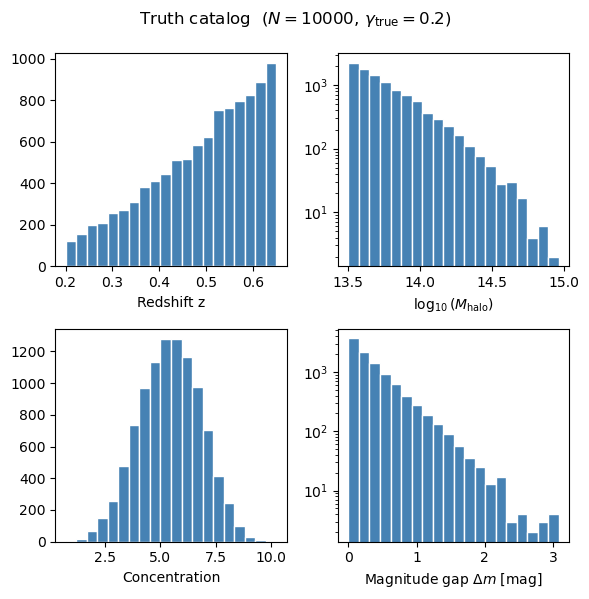

In [5]:
fig, axes = plt.subplots(2,2, figsize=(6,6))

axes[0,0].hist(truth['z'], bins=20, color='steelblue', edgecolor='white')
axes[0,0].set_xlabel('Redshift z')

axes[0,1].hist(np.log10(truth['M_halo']), bins=20, color='steelblue', edgecolor='white')
axes[0,1].set_xlabel(r'$\log_{10}(M_{\rm halo})$')
axes[0,1].set_yscale('log')

axes[1,0].hist(truth['concentration'], bins=20, color='steelblue', edgecolor='white')
axes[1,0].set_xlabel('Concentration')

axes[1,1].hist(truth['delta_m'], bins=20, color='steelblue', edgecolor='white')
axes[1,1].set_xlabel(r'Magnitude gap $\Delta m$ [mag]')
axes[1,1].set_yscale('log')

#for ax in axes: ax.set_ylabel('Count')
plt.suptitle(
    rf'Truth catalog  ($N={N_CLUSTERS}$, $\gamma_{{\rm true}}={TRUE_GAMMA}$)',
    y=.99,
)
plt.tight_layout(); plt.show()

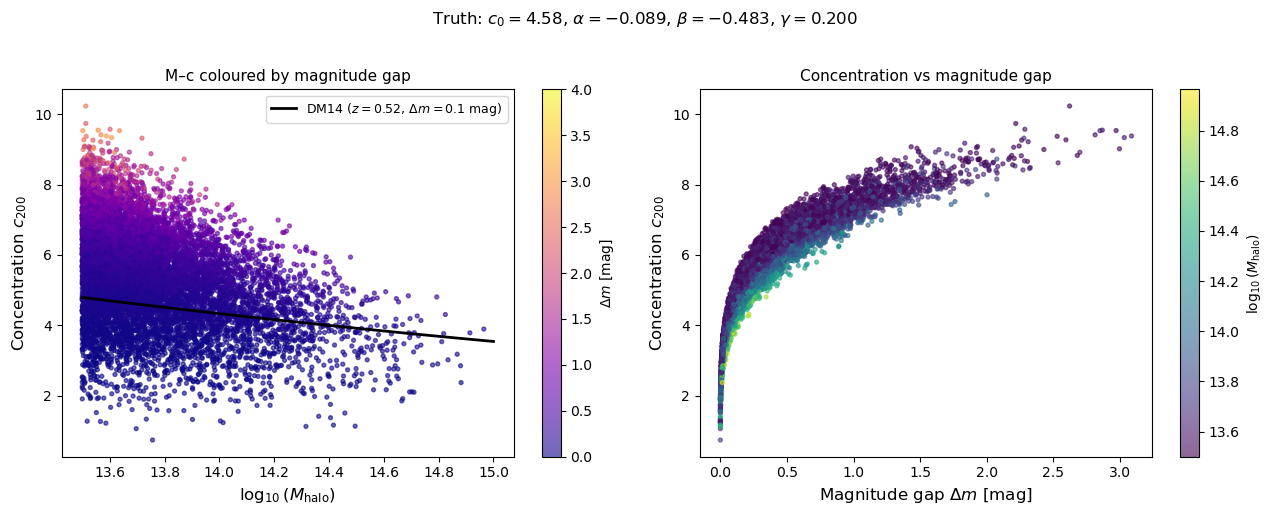

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# M–c scatter coloured by delta_m
ax = axes[0]
sc = ax.scatter(logM_s, truth['concentration'],
                c=truth['delta_m'], cmap='plasma', s=8, alpha=0.6,
                vmin=0, vmax=4, rasterized=True)
plt.colorbar(sc, ax=ax, label=r'$\Delta m$ [mag]')
z_med  = float(np.median(truth['z']))
M_grid = np.logspace(13.5, 15.0, 200)
C_dm0  = c_DuttonMaccio(z_med * np.ones(200), M_grid, c=1.0)
ax.plot(np.log10(M_grid), C_dm0, 'k-', lw=2,
        label=rf'DM14 ($z={z_med:.2f}$, $\Delta m={DELTA_M_REF}$ mag)')
ax.set_xlabel(r'$\log_{10}(M_{\rm halo})$', fontsize=12)
ax.set_ylabel(r'Concentration $c_{200}$', fontsize=12)
ax.set_title('M–c coloured by magnitude gap', fontsize=11)
ax.legend(fontsize=9)

# c vs delta_m coloured by log M
ax = axes[1]
sc2 = ax.scatter(truth['delta_m'], truth['concentration'],
                 c=logM_s, cmap='viridis', s=8, alpha=0.6, rasterized=True)
plt.colorbar(sc2, ax=ax, label=r'$\log_{10}(M_{\rm halo})$')
ax.set_xlabel(r'Magnitude gap $\Delta m$ [mag]', fontsize=12)
ax.set_ylabel(r'Concentration $c_{200}$', fontsize=12)
ax.set_title(r'Concentration vs magnitude gap', fontsize=11)

plt.suptitle(
    rf'Truth: $c_0={c0_true:.2f}$, $\alpha={alpha_true:.3f}$, '
    rf'$\beta={beta_true:.3f}$, $\gamma={gamma_true:.3f}$',
    y=1.02, fontsize=12,
)
plt.tight_layout(); plt.show()

## 2 — Triaxial shapes

Projected q_min/q_maj: median=0.69, range [0.31, 1.00]


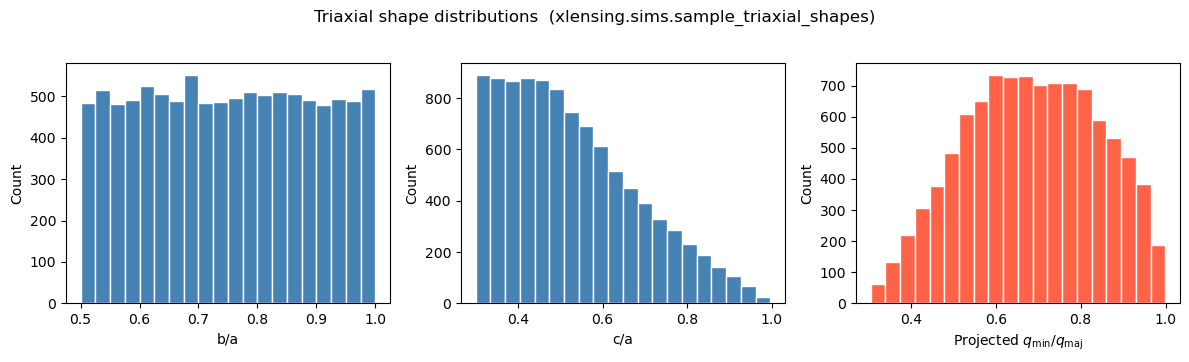

In [7]:
_seed_tri = _seed(10)
rng_tri = np.random.default_rng(_seed_tri)

shapes = sample_triaxial_shapes(
    truth['z'], truth['M_halo'],
    ba_range=(0.5, 1.0), ca_lo=0.3, isotropic_los=True,
    rng=rng_tri,
)
r_vir_vals    = shapes['r_vir']
q_ba          = shapes['q_ba']
q_ca          = shapes['q_ca']
theta_los_arr = shapes['theta_los']
phi_los_arr   = shapes['phi_los']
q_maj_arr     = shapes['q_maj']
q_min_arr     = shapes['q_min']
pa_arr        = shapes['pa']

print(f'Projected q_min/q_maj: '
      f'median={np.median(q_min_arr/q_maj_arr):.2f}, '
      f'range [{(q_min_arr/q_maj_arr).min():.2f}, {(q_min_arr/q_maj_arr).max():.2f}]')

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].hist(q_ba, bins=20, color='steelblue', edgecolor='white')
axes[0].set_xlabel('b/a')
axes[1].hist(q_ca, bins=20, color='steelblue', edgecolor='white')
axes[1].set_xlabel('c/a')
axes[2].hist(q_min_arr / q_maj_arr, bins=20, color='tomato', edgecolor='white')
axes[2].set_xlabel(r'Projected $q_{\rm min}/q_{\rm maj}$')
for ax in axes: ax.set_ylabel('Count')
plt.suptitle('Triaxial shape distributions  (xlensing.sims.sample_triaxial_shapes)',
             y=1.02)
plt.tight_layout(); plt.show()


## 3 — Miscentering offsets

A fraction $1 - f_{\rm cen}$ of clusters are assigned a random positional offset
between the true NFW centre and the measured lensing centre.  The offset
magnitude is drawn from a **Rayleigh distribution** with scale $\sigma_{\rm off}$:
$$
P(r) = \frac{r}{\sigma_{\rm off}^2}\exp\!\left(-\frac{r^2}{2\sigma_{\rm off}^2}\right),\quad r\ge0.
$$
The direction is uniform on the sky.  The offsets are computed in physical Mpc
at the cluster redshift and converted to radians per cluster.  Inside the
lensing worker, the measurement centre passed to
`metacal_cluster_lensing` is displaced by this offset, while the true NFW shear
is still applied around $(0,0)$.


Miscentred clusters : 3643 / 10000 (36.4%)
sigma_off           : 0.32 Mpc/h  =  0.473 Mpc
Mean Rayleigh offset: 0.593 Mpc  (sigma_off * sqrt(pi/2))
Median offset (miscentred sample): 0.559 Mpc


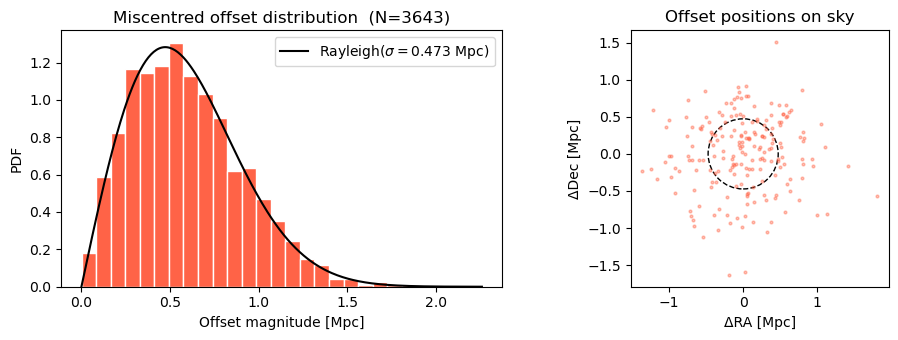

In [8]:
from astropy.cosmology import Planck18 as _planck18

h = float(_planck18.h)                     # ≈ 0.674
SIGMA_OFF_MPC = SIGMA_OFF_MPC_H / h        # convert Mpc/h → physical Mpc

_seed_mis = _seed(20)
rng_mis = np.random.default_rng(_seed_mis)

is_miscentered = rng_mis.uniform(0, 1, N_CLUSTERS) > F_CEN

off_mag_mpc = np.where(
    is_miscentered,
    rng_mis.rayleigh(scale=SIGMA_OFF_MPC, size=N_CLUSTERS),
    0.0,
)
phi_mis = rng_mis.uniform(0, 2 * np.pi, N_CLUSTERS)

n_mis = int(is_miscentered.sum())
print(f'Miscentred clusters : {n_mis} / {N_CLUSTERS} ({100*n_mis/N_CLUSTERS:.1f}%)')
print(f'sigma_off           : {SIGMA_OFF_MPC_H} Mpc/h  =  {SIGMA_OFF_MPC:.3f} Mpc')
print(f'Mean Rayleigh offset: {SIGMA_OFF_MPC * np.sqrt(np.pi/2):.3f} Mpc'
      f'  (sigma_off * sqrt(pi/2))')
if n_mis > 0:
    print(f'Median offset (miscentred sample): '
          f'{np.median(off_mag_mpc[is_miscentered]):.3f} Mpc')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(off_mag_mpc[is_miscentered], bins=25,
             color='tomato', edgecolor='white', density=True)
r_grid = np.linspace(0, off_mag_mpc.max() * 1.1, 300)
pdf_ray = r_grid / SIGMA_OFF_MPC**2 * np.exp(-r_grid**2 / (2 * SIGMA_OFF_MPC**2))
axes[0].plot(r_grid, pdf_ray, 'k-', lw=1.5,
             label=rf'Rayleigh($\sigma={SIGMA_OFF_MPC:.3f}$ Mpc)')
axes[0].set_xlabel('Offset magnitude [Mpc]')
axes[0].set_ylabel('PDF')
axes[0].set_title(f'Miscentred offset distribution  (N={n_mis})')
axes[0].legend()

for r_i, ph_i in zip(off_mag_mpc[is_miscentered][:200],
                     phi_mis[is_miscentered][:200]):
    axes[1].plot(r_i * np.cos(ph_i), r_i * np.sin(ph_i),
                 'o', color='tomato', ms=2, alpha=0.4)
axes[1].add_patch(plt.Circle((0,0), SIGMA_OFF_MPC, fill=False, ls='--',
                             color='k', lw=1))
axes[1].set_aspect('equal')
axes[1].set_xlabel('ΔRA [Mpc]')
axes[1].set_ylabel('ΔDec [Mpc]')
axes[1].set_title('Offset positions on sky')
plt.tight_layout(); plt.show()


## 4 — Simulate triaxial NFW lensing with miscentering

In [9]:
%%time
import multiprocess as mp
from scipy.interpolate import interp1d
import xlensing.cosmo as _xlc
import xlensing.sims as _xlsims

# ── DA spline patch ────────────────────────────────────────────────────────
_z_tab    = np.linspace(0.0, 3.0, 5000)
_chi_tab  = _xlc.cosmology.comoving_distance(_z_tab).value
_chi_of_z = interp1d(_z_tab, _chi_tab, kind='linear',
                     bounds_error=False, fill_value='extrapolate')

def _DA_fast(z1, z2):
    z2_a = np.atleast_1d(np.asarray(z2, dtype=float))
    res  = (_chi_of_z(z2_a) - float(_chi_of_z(float(z1)))) / (1.0 + z2_a)
    return float(res[0]) if np.ndim(z2) == 0 else res

_xlc.DA    = _DA_fast
_xlsims.DA = _DA_fast

# Per-cluster catalogue: fresh positions + redshifts + responses + shapes,
# with Poisson fluctuation around the expected (density * area) count.

def _process_cluster(i):
    z_i = float(truth['z'][i])
    M_i = float(truth['M_halo'][i])
    c_i = float(truth['concentration'][i])
    a_i = r_vir_vals[i]

    # ── Independent random background catalogue for this cluster ──
    gal_i = make_simple_random_cat(
        DENSITY, WIDTH_RAD, Z_SRC_RANGE, shape_noise=0.0,
        seed=_seed(4000 + i),
        poisson_density=True,
    ).T
    n_gals = len(gal_i)

    # Replace source z with DES Y3 source n(z)
    rng_src = np.random.default_rng(_seed(5000 + i))
    gal_i[:, 2] = sample_des_y3_source_z(
        n_gals, rng_src,
        z_min=Z_SRC_RANGE[0], z_max=Z_SRC_RANGE[1],
        alpha=DES_Y3_Z_SRC_ALPHA, beta=DES_Y3_Z_SRC_BETA, z0=DES_Y3_Z_SRC_Z0,
    )

    # Lognormal-size based metacal responses
    rng_resp = np.random.default_rng(_seed(6000 + i))
    sizes  = rng_resp.lognormal(mean=np.log(0.5), sigma=0.5, size=n_gals)
    R_RESP = np.clip(1.0 - (sizes / 1.5) ** 2, 0.05, 0.99)
    gal_i[:, 5] = R_RESP   # R11
    gal_i[:, 6] = 0.0
    gal_i[:, 7] = 0.0
    gal_i[:, 8] = R_RESP   # R22

    # Intrinsic shapes (drawn AFTER we know the actual n_gals)
    rng_sh = np.random.default_rng(_seed(1000 + i))
    sp_i = ngmix.priors.shape.GPriorBA(sigma=SHAPE_NOISE, rng=rng_sh)
    e1, e2 = sp_i.sample2d(n_gals)
    gal_i[:, 3] = e1
    gal_i[:, 4] = e2

    # Source-z cut behind the lens
    mc_mask = gal_i[:, 2] > 1.1 * z_i + 0.2
    gal_mc  = gal_i[mc_mask]
    if len(gal_mc) < 20:
        return i, None, None

    # Apply triaxial NFW shear around the TRUE cluster centre (0, 0)
    cluster_arr = [0., 0., z_i, M_i, c_i,
                   a_i, q_ba[i] * a_i, q_ca[i] * a_i,
                   theta_los_arr[i], phi_los_arr[i]]
    gal_sheared = apply_triaxial_NFW_shear_region(cluster_arr, gal_mc)

    sources_mc = gal_sheared[:, [0, 1, 2, 3, 4, 9, 5, 6, 7, 8]]
    radius_mpc = WIDTH_RAD * _DA_fast(0, z_i)

    # Miscentering offset for the measurement centre
    DA_i      = _DA_fast(0, z_i)
    off_rad_i = off_mag_mpc[i] / DA_i
    cen_ra_i  = off_rad_i * np.cos(phi_mis[i])
    cen_dec_i = off_rad_i * np.sin(phi_mis[i])

    bg = metacal_cluster_lensing((cen_ra_i, cen_dec_i, z_i), sources_mc.T, radius_mpc)
    if bg['Count'] < 20:
        return i, None, None

    stake = np.array([
        bg['Critical Density'], bg['Tangential Shear'], bg['Cross Shear'],
        bg['Weights'], bg['Radial Distance'], bg['Mult. Bias'],
    ])
    sig_t, _ = signal(stake, bin_limits)
    dv = np.nan_to_num(sig_t, nan=0.0)

    R      = bg['Radial Distance']
    in_bin = (R[:, None] > bin_limits[:, 0]) & (R[:, None] < bin_limits[:, 1])
    cov_d  = np.full(N_BINS, NOISE_FLOOR_COV)
    for b in range(N_BINS):
        m   = in_bin[:, b]
        n_b = m.sum()
        if n_b >= 5:
            cov_d[b] = (SHAPE_NOISE * bg['Critical Density'][m].mean()
                        / np.sqrt(n_b)) ** 2

    return i, dv, cov_d

# Output arrays
data_vectors = np.zeros((N_CLUSTERS, N_BINS))
cov_matrices = np.full((N_CLUSTERS, N_BINS, N_BINS), 0.0)
for i in range(N_CLUSTERS):
    np.fill_diagonal(cov_matrices[i], NOISE_FLOOR_COV)

# Parallel dispatch
N_WORKERS = 15
with mp.Pool(N_WORKERS) as pool:
    for idx, dv, cov_d in tqdm(
        pool.imap(_process_cluster, range(N_CLUSTERS), chunksize=10),
        total=N_CLUSTERS, desc='Triaxial + miscentering lensing',
    ):
        if dv is not None:
            data_vectors[idx] = dv
            np.fill_diagonal(cov_matrices[idx], cov_d)

non_empty = (np.diagonal(cov_matrices, axis1=1, axis2=2) < NOISE_FLOOR_COV).sum(1).mean()
print(f'\nNon-empty bins per cluster: {non_empty:.1f} / {N_BINS}')


Triaxial + miscentering lensing:   0%|          | 0/10000 [00:00<?, ?it/s]

Process ForkPoolWorker-6:
Process ForkPoolWorker-14:
Process ForkPoolWorker-12:
Process ForkPoolWorker-9:
Process ForkPoolWorker-5:
Process ForkPoolWorker-2:
Process ForkPoolWorker-3:
Process ForkPoolWorker-15:


CPU times: user 740 ms, sys: 326 ms, total: 1.07 s
Wall time: 14.8 s


KeyboardInterrupt: 

In [ ]:
# Sanity check: six example profiles, coloured by delta_m
# Circles = centred clusters, triangles = miscentred clusters
idx = np.round(np.linspace(0, N_CLUSTERS - 1, 6)).astype(int)
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True)

cmap_dm = plt.cm.plasma
dm_all  = np.asarray(truth['delta_m'])
vmin, vmax = 0.0, float(np.nanpercentile(dm_all, 95))

for ax, i in zip(axes.ravel(), idx):
    errs = np.sqrt(np.diag(cov_matrices[i]))
    real = errs < np.sqrt(NOISE_FLOOR_COV)
    dm_i = float(truth['delta_m'][i])
    col  = cmap_dm((dm_i - vmin) / (vmax - vmin))
    marker = '^' if is_miscentered[i] else 'o'
    ax.errorbar(RADII[real], data_vectors[i, real], yerr=errs[real],
                fmt=marker, markersize=4, capsize=4, color=col)
    ax.set_xscale('log'); ax.set_yscale('log')
    mis_str = f'off={off_mag_mpc[i]:.2f} Mpc' if is_miscentered[i] else 'centred'
    ax.set_title(
        rf'$z={truth["z"][i]:.2f}$  '
        rf'$\log M={np.log10(truth["M_halo"][i]):.2f}$  '
        rf'$\Delta m={dm_i:.2f}$  {mis_str}',
        fontsize=9,
    )
    ax.set_xlabel('R [Mpc]')
    ax.set_ylabel(r'$\Delta\Sigma$ [M$_\odot$/pc$^2$]')

plt.suptitle(
    'Sample ΔΣ profiles (colour = magnitude gap; ▲ = miscentred cluster)',
    y=1.01,
)
plt.tight_layout(); plt.show()


## 5 — Cluster observable table

Richness from the deterministic McClintock+18 inversion of the true mass
(`poisson_richness=False`) — no Eddington bias.  The `delta_m` column from the
truth catalog is passed through for the gamma term in the forward model.

In [ ]:
_seed_obs = _seed(1)

cluster_obs, _, _ = make_test_data(
    truth, RADII,
    fractional_noise=0.2,
    poisson_richness=False,
    seed=_seed_obs,
)

print(f'Columns: {cluster_obs.colnames}')
print(f'Richness:  {cluster_obs["Lambda"].min():.1f} – {cluster_obs["Lambda"].max():.1f}')
print(f'delta_m:   {cluster_obs["delta_m"].min():.2f} – {cluster_obs["delta_m"].max():.2f}')
cluster_obs[:5]


## 6 — Diagnostic: triaxiality-induced residuals vs spherical NFW

For each cluster $i$, evaluate the **spherical NFW** prediction
$\Delta\Sigma^{\rm NFW}_i(R)$ at the cluster's **true** $(M, c, z)$ and compare it
to the simulated profile.  Because the simulation applies a triaxial NFW shear
with a random LOS orientation, the residual

$$
\delta_i(R) \;\equiv\; \Delta\Sigma^{\rm data}_i(R) \;-\; \Delta\Sigma^{\rm NFW}_i(R;\,M_i, c_i, z_i)
$$

isolates the **shape mismatch** (no fitting parameters involved).  Expected
behaviour:

- **Per-cluster scatter** in $\delta_i(R)$ is large at small $R$ (NFW peak
  amplitude is shape-sensitive) and decreases at large $R$ (the $1/R^2$ tail is
  approximately shape-independent).
- **Median** of $\delta_i(R) / \Delta\Sigma^{\rm NFW}_i(R)$ shows a small
  systematic offset reflecting the difference between the orientation-averaged
  triaxial profile and spherical NFW; this offset is the source of the parameter
  bias.


In [ ]:
from destacking.model import _nfw_profiles

# Spherical NFW prediction per cluster using TRUE parameters
truth_profiles = _nfw_profiles(
    np.asarray(truth['z']),
    np.asarray(truth['M_halo']),
    np.asarray(truth['concentration']),
    RADII,
)

# Per-cluster residual (absolute and fractional)
residuals = data_vectors - truth_profiles                  # (N, N_bins)
frac_res  = residuals / np.where(truth_profiles > 0, truth_profiles, np.nan)

# Mask out radial bins that received the NOISE_FLOOR_COV (empty bins)
errs       = np.sqrt(np.diagonal(cov_matrices, axis1=1, axis2=2))   # (N, N_bins)
real_mask  = errs < np.sqrt(NOISE_FLOOR_COV)
frac_res_m = np.where(real_mask, frac_res, np.nan)

med = np.nanmedian(frac_res_m, axis=0)
p16 = np.nanpercentile(frac_res_m, 16, axis=0)
p84 = np.nanpercentile(frac_res_m, 84, axis=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# ── Panel 1: fractional residuals vs R ──
ax = axes[0]
ax.fill_between(RADII, p16, p84, color='steelblue', alpha=0.25,
                label='16–84% per-cluster spread')
ax.plot(RADII, med, '-o', color='steelblue', label='Median')
ax.axhline(0.0, color='k', lw=0.5, ls=':')
ax.axvline(R_MIN_FIT, color='crimson', lw=1.5, ls='--',
           label=f'R_MIN_FIT = {R_MIN_FIT} Mpc')
ax.set_xscale('log')
ax.set_xlabel('R [Mpc]')
ax.set_ylabel(r'$(\Delta\Sigma_{\rm data} - \Delta\Sigma_{\rm NFW,truth}) / \Delta\Sigma_{\rm NFW,truth}$')
ax.set_title('Per-cluster fractional residual vs spherical NFW (truth params)')
ax.set_ylim(-1.5, 1.5)
ax.legend(fontsize=9)

# ── Panel 2: per-cluster scatter (sigma of the residual) vs R ──
ax = axes[1]
sigma_res = (p84 - p16) / 2.0
ax.plot(RADII, sigma_res, '-o', color='tomato', label='Triaxiality scatter (half 68% spread)')
ax.axvline(R_MIN_FIT, color='crimson', lw=1.5, ls='--')
ax.set_xscale('log')
ax.set_xlabel('R [Mpc]')
ax.set_ylabel(r'$\sigma_{\rm res}$ (fractional)')
ax.set_title('Per-cluster fractional scatter vs R')
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

print('Median fractional residual per bin:')
for r, m, s in zip(RADII, med, sigma_res):
    cut = ' (KEPT)' if r >= R_MIN_FIT else ' (cut)'
    print(f'  R = {r:6.3f} Mpc :  median = {m:+.3f},  σ = {s:.3f}{cut}')


## 7 — Apply the radial cut

Discard radial bins below `R_MIN_FIT` from the data, covariance, and radii.
The simulation arrays are kept intact; only the slice fed into the sampler is
restricted.


In [ ]:
keep_mask = RADII >= R_MIN_FIT
n_kept    = int(keep_mask.sum())

RADII_fit         = RADII[keep_mask]
data_vectors_fit  = data_vectors[:, keep_mask]
cov_matrices_fit  = cov_matrices[:, keep_mask][:, :, keep_mask]

print(f'Total bins  : {len(RADII)}')
print(f'Kept bins   : {n_kept}  (R >= {R_MIN_FIT} Mpc)')
print(f'Radii used  : {np.round(RADII_fit, 3)}')
print(f'data_vectors_fit.shape = {data_vectors_fit.shape}')
print(f'cov_matrices_fit.shape = {cov_matrices_fit.shape}')


## 8 — Priors

Priors are declared **explicitly** as a dictionary mapping parameter name to a
frozen `scipy.stats` distribution, then passed to `run_sampler_combined` via
the `priors` keyword.  This makes the priors first-class objects we can
visualise and overlay on the posterior plots below.


In [ ]:
# Priors centred on the expected Dutton-Maccio (2014) power-law fit to the
# sample.  These are intentionally TIGHT around the DM14 truth: the assumption
# is that the M-c relation is pre-determined and we are only fitting for the
# magnitude-gap correction (gamma).  The remaining sampled parameters are kept
# free with narrow, informative priors so that small departures induced by a
# non-zero gamma can still be absorbed.
PRIORS = {
    'c0':         sp_norm(loc=4.57,  scale=0.05),     # DM14 c at M=1e14, z~z_ref
    'alpha':      sp_norm(loc=-0.1, scale=0.05),    # DM14 mass slope
    'beta':       sp_norm(loc=-0.4, scale=0.2),     # DM14 redshift slope
    'gamma':      sp_norm(loc=0.0,  scale=1.0),     # Gaussian, scale 1
    'log_M_norm': sp_norm(loc=0.0,  scale=0.1),     # mass-richness calibration
}

PRIOR_LABELS = {
    'c0':         r'$c_0$',
    'alpha':      r'$\alpha$',
    'beta':       r'$\beta$',
    'gamma':      r'$\gamma$',
    'log_M_norm': r'$\log M_{\rm norm}$',
}

for name, dist in PRIORS.items():
    print(f'  {name:<12}  {dist.dist.name:<10}  '
          f'mean={dist.mean():+.3f}, std={dist.std():.3f}')


## 9 — Fixed miscentering in the forward model

The miscentering model is held **fixed at the population values used in the
simulation**, identical for every cluster:

- `FMISS_FIT[i] = 1 - F_CEN = 0.36` for all $i$
- `SIGMA_OFF_FIT[i] = SIGMA_OFF_MPC = SIGMA_OFF_MPC_H / h` for all $i$

The forward model now uses
`xlensing.model.NFW_Delta_Sigma['Signal'] − ['Two-halo term']`, which is the
one-halo mixture
$(1 - {\rm FMISS})\,\Delta\Sigma_{\rm NFW} + {\rm FMISS}\,
\Delta\Sigma_{\rm miscentred}$ (with the BCG term, which is zero here).
The two-halo term is excluded because the simulation contains only the one-halo
triaxial NFW signal.

The chain still samples only $(c_0, \alpha, \beta, \gamma, \log M_{\rm norm})$
— miscentering is **not** a free parameter.


In [ ]:
# Population-level miscentering model (the same for every cluster).
#   FMISS[i]     = 1 - F_CEN  for every i  (≈ 0.36 with F_CEN = 0.64)
#   SIGMA_OFF[i] = SIGMA_OFF_MPC for every i  (= SIGMA_OFF_MPC_H / h)
# These are the population parameters used to GENERATE the offsets; we hold
# them fixed in the fit rather than sampling them.
FMISS_FIT     = np.full(N_CLUSTERS, 1.0 - F_CEN)
SIGMA_OFF_FIT = np.full(N_CLUSTERS, SIGMA_OFF_MPC)

print(f'FMISS_FIT     : {FMISS_FIT[0]:.3f}  (uniform; = 1 - F_CEN = 1 - {F_CEN})')
print(f'SIGMA_OFF_FIT : {SIGMA_OFF_FIT[0]:.3f} Mpc  (uniform; = {SIGMA_OFF_MPC_H} Mpc/h)')


## 10 — Run the combined sampler (cut data)

The sampler and forward model are **unchanged**.  Only the data, covariance, and
`radii` array fed in are restricted by the radial cut.


In [ ]:
sampler = run_sampler_combined(
    cluster_obs,
    data_vectors_fit,
    cov_matrices_fit,
    RADII_fit,
    priors=PRIORS,                # explicit priors declared above
    delta_m_ref=DELTA_M_REF,
    fit_beta=True,
    FMISS=FMISS_FIT,              # uniform population miscentering fraction
    SIGMA_OFF=SIGMA_OFF_FIT,      # uniform population Rayleigh scale [physical Mpc]
    n_live=400,
    pool=15,
    verbose=True,
)


## 11 — Posterior analysis

In [ ]:
points, log_w, log_l = sampler.posterior()
weights = np.exp(log_w - log_w.max())
weights /= weights.sum()

# Parameter order: c0, alpha, beta, gamma, log_M_norm
c0_s    = points[:, 0]
alpha_s = points[:, 1]
beta_s  = points[:, 2]
gamma_s = points[:, 3]
MN_s    = points[:, 4]

def wq(v, q):
    sorter = np.argsort(v)
    cs = np.cumsum(weights[sorter]) / weights.sum()
    return np.interp(q, cs, v[sorter])

truths_list = [c0_true, alpha_true, beta_true, gamma_true, 0.0]
names_list  = ['c0', 'alpha', 'beta', 'gamma', 'log_M_norm']
samples_list = [c0_s, alpha_s, beta_s, gamma_s, MN_s]

results = {}
print(f'{"param":<14} {"median":>10}  {"−1σ":>8}  {"+1σ":>8}  {"truth":>10}  {"bias":>8}')
print('-' * 65)
for name, samp, tv in zip(names_list, samples_list, truths_list):
    lo, md, hi = wq(samp, 0.16), wq(samp, 0.50), wq(samp, 0.84)
    sigma = (hi - lo) / 2
    bias  = (md - tv) / sigma if sigma > 0 else np.nan
    results[name] = (lo, md, hi, tv, bias)
    flag = '  ✓' if abs(bias) < 2 else '  BIASED'
    print(f'{name:<14} {md:>+10.4f}  {md-lo:>8.4f}  {hi-md:>8.4f}'
          f'  {tv:>+10.4f}  {bias:>+7.2f}σ{flag}')

In [ ]:
if corner is not None:
    # Parameter order matches the sampler's add_parameter sequence
    param_order = ['c0', 'alpha', 'beta', 'gamma', 'log_M_norm']
    labels      = [PRIOR_LABELS[n] for n in param_order]

    fig = corner.corner(
        points,
        weights=weights,
        labels=labels,
        truths=truths_list,
        truth_color='crimson',
        show_titles=True,
        title_fmt='.3f',
        smooth=1.0,
        color='steelblue',
        hist_kwargs={'density': True},
    )

    # Overlay the priors on the 1D marginal histograms (the diagonal axes)
    ndim = points.shape[1]
    axes = np.array(fig.axes).reshape((ndim, ndim))
    for i, name in enumerate(param_order):
        ax = axes[i, i]
        xlim = ax.get_xlim()
        x_grid = np.linspace(xlim[0], xlim[1], 400)
        pdf_vals = PRIORS[name].pdf(x_grid)
        if np.any(np.isfinite(pdf_vals) & (pdf_vals > 0)):
            ax.plot(x_grid, pdf_vals,
                    color='darkorange', lw=1.6, ls='--', alpha=0.9,
                    zorder=5)

    # Legend explaining the colours
    from matplotlib.lines import Line2D
    handles = [
        Line2D([0], [0], color='steelblue',  lw=2,            label='Posterior'),
        Line2D([0], [0], color='darkorange', lw=1.6, ls='--', label='Prior'),
        Line2D([0], [0], color='crimson',    lw=1.5,          label='Truth'),
    ]
    fig.legend(handles=handles, loc='upper right',
               bbox_to_anchor=(0.98, 0.98), fontsize=11, frameon=True)

    plt.suptitle(
        rf'Combined M–c + $\gamma$ recovery — triaxial + miscentering 'rf'  ($f_{{\rm cen}}={F_CEN}$, $\sigma_{{\rm off}}={SIGMA_OFF_MPC_H}$ Mpc/$h$, 'rf'  radial cut $R \geq {R_MIN_FIT}$ Mpc)'
        rf'  ($N={N_CLUSTERS}$, $\gamma_{{\rm true}}={TRUE_GAMMA}$)',
        y=1.01, fontsize=11,
    )
    plt.savefig('combined_posterior_triaxial_miscentering_unbiased.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('Install corner for the triangle plot.')


## 12 — M–c recovery band at fixed magnitude gap

Shows posterior concentration bands at three representative $\Delta m$ values
against the DM14 truth curves.  The gamma term tilts the band relative to the
reference $\Delta m = \Delta m_{\rm ref}$ curve.

In [ ]:
M_grid  = np.logspace(13.5, 15.0, 200)
logM_g  = np.log10(M_grid)
z_med   = float(np.median(truth['z']))
logz1_g = np.log10((1 + z_med) / (1 + _MC_Z_REF))

dm_show    = [0.5, DELTA_M_REF, 2.0]
colors     = ['royalblue', 'steelblue', 'teal']
colors_tru = ['navy', 'darkblue', 'darkcyan']

rng_plot = np.random.default_rng(0)
idx_band = rng_plot.choice(len(c0_s), size=300,
                           p=weights / weights.sum(), replace=True)

fig, ax = plt.subplots(figsize=(9, 6))

for dm_val, col, col_t in zip(dm_show, colors, colors_tru):
    log_dm_r = np.log10(max(dm_val, 1e-6) / DELTA_M_REF)
    label_dm = rf'$\Delta m = {dm_val:.1f}$ mag'

    C_band = np.array([
        10.0 ** (np.log10(c0_s[k])
                 + alpha_s[k] * (logM_g - _MC_M_PIVOT_LOG)
                 + beta_s[k]  * logz1_g
                 + gamma_s[k] * log_dm_r)
        for k in idx_band
    ])
    ax.fill_between(logM_g, C_band.min(0), C_band.max(0),
                    alpha=0.20, color=col)

    _, md_c, _, _, _ = results['c0']
    _, md_a, _, _, _ = results['alpha']
    _, md_b, _, _, _ = results['beta']
    _, md_g, _, _, _ = results['gamma']
    C_med = 10.0 ** (np.log10(md_c) + md_a * (logM_g - _MC_M_PIVOT_LOG)
                     + md_b * logz1_g + md_g * log_dm_r)
    ax.plot(logM_g, C_med, color=col, lw=2, label=f'Posterior median ({label_dm})')

    c_piv_true = 1.0 * (max(dm_val, 1e-6) / DELTA_M_REF) ** TRUE_GAMMA
    C_true = c_DuttonMaccio(z_med * np.ones(200), M_grid, c=c_piv_true)
    ax.plot(logM_g, C_true, '--', color=col_t, lw=1.5,
            label=f'DM14 truth ({label_dm})')

sc = ax.scatter(logM_s, truth['concentration'],
                c=truth['delta_m'], cmap='plasma', s=5, alpha=0.25,
                vmin=0, vmax=4, rasterized=True, zorder=0)
plt.colorbar(sc, ax=ax, label=r'$\Delta m$ [mag]')

ax.set_xlabel(r'$\log_{10}(M_{\rm halo}\,/\,M_\odot)$', fontsize=13)
ax.set_ylabel(r'Concentration $c_{200}$', fontsize=13)
ax.set_title(
    rf'Combined M–c + $\gamma$ recovery — triaxial + miscentering'
    rf'  ($f_{{\rm cen}}={F_CEN}$, '
    rf'$\sigma_{{\rm off}}={SIGMA_OFF_MPC_H}$ Mpc/$h$, cut $R \geq {R_MIN_FIT}$ Mpc)',
    fontsize=11,
)
ax.set_ylim([0.,10])
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig('combined_mc_recovery_triaxial_miscentering_unbiased.png', dpi=150)
plt.show()


## 13 — Gamma marginal posterior

In [ ]:
lo_g, md_g, hi_g, tv_g, bias_g = results['gamma']

fig, ax = plt.subplots(figsize=(7, 4.5))

# Posterior histogram
ax.hist(gamma_s, weights=weights, bins=40, density=True,
        color='steelblue', alpha=0.65, edgecolor='white', label='Posterior')

# 68% CI band and median
ax.axvspan(lo_g, hi_g, alpha=0.20, color='steelblue',
           label=rf'68% CI  [{lo_g:.3f}, {hi_g:.3f}]')
ax.axvline(md_g, color='steelblue', lw=1.5, ls='-',
           label=rf'Median $\hat{{\gamma}}$ = {md_g:.3f}')

# Truth marker
ax.axvline(tv_g, color='crimson', lw=2.0, ls='--',
           label=rf'True $\gamma$ = {tv_g:.3f}')

# Prior overlay (on the same density-normalised scale)
xlim = ax.get_xlim()
x_grid = np.linspace(xlim[0], xlim[1], 400)
ax.plot(x_grid, PRIORS['gamma'].pdf(x_grid),
        color='darkorange', lw=2.0, ls='--',
        label=f'Prior  ({PRIORS["gamma"].dist.name})')

ax.set_xlabel(r'$\gamma$  (magnitude-gap concentration slope)', fontsize=13)
ax.set_ylabel('Density', fontsize=12)
ax.set_title(
    rf'$\gamma$ marginal — combined fit  ({N_CLUSTERS} triaxial + miscentered clusters,'
    rf'  $f_{{\rm cen}}={F_CEN}$, cut $R \geq {R_MIN_FIT}$ Mpc, bias = {bias_g:+.2f}σ)',
    fontsize=11,
)
ax.legend(fontsize=9, loc='upper right')
plt.tight_layout()
plt.savefig('combined_gamma_marginal_triaxial_miscentering_unbiased.png', dpi=150)
plt.show()

print('\n--- Final summary ---')
for name, (lo, mdv, hi, tv, bias) in results.items():
    flag = 'OK' if abs(bias) < 2 else 'BIASED'
    print(f'  {name:<14}: {mdv:+.4f}  truth {tv:+.4f}  bias {bias:+.2f}σ  [{flag}]')
